In [4]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('/mnt/c/muco/mucol/optics')
from hybrid_qp import length_qp_normal, find_largest_n_with_dividers
from class_geometry.ring_geometry.ring_geometry import RingGeometry, load_file
from generate_fodo_normal import DS_normal
from generate_fodo import plot_twiss, plot_chroma
from tracking.TrackingRCS import TrackingRCS, off_dE, on_dE
from generate_fodo_normal import save_para, save_table, save_tunes
from pathlib import Path


plt.rc('axes', labelsize=12)     # fontsize of the x and y labels
plt.rc('xtick', labelsize=11)    # fontsize of the tick labels
plt.rc('ytick', labelsize=11)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize

STEP_QUAD = 1e-8
STEP_SXT = 1e-4

RF_FREQUENCY = 1.3e9

/home/ls276867/.venvs/xsuite/lib/python3.11/site-packages/xplt/hooks.py:31: RuntimeWarning: Failed to register formatters with pint: No module named 'pint'
  warnings.warn(f"Failed to register formatters with pint: {e}", RuntimeWarning)


ModuleNotFoundError: No module named 'EB_tracking'

In [ ]:
mu = np.pi/2
n_size = 3
rcs_name = 'RCS1_gf'

path = Path(__file__).resolve().parent
input = load_file(path / 'FODO_cells_energy_spread.json')

sigma_delta = input[rcs_name]['sig_delta_N_'+f'{n_size}']
file_input = input[rcs_name]['file']
n_turn_rcs = input[rcs_name]['n_turn_rcs']

rcs = RingGeometry(file_input = file_input)
n_cell_qpN, cell_length_qpN, qp_para_qpN, r_qp_qpN = length_qp_normal(
    rcs, 
    mu=mu, 
    sigma_delta=sigma_delta, 
    slice=False
    )
l_qp_nc_qpN, k_nc_ext_qpN, gradient_nc_ext_qpN = qp_para_qpN['qp_nc']['length'], qp_para_qpN['qp_nc']['k'], qp_para_qpN['qp_nc']['gradient']
mask = gradient_nc_ext_qpN * r_qp_qpN < 1

# If we want to work with maximum number of cells
# n_cell_tot_N, nb_arc_N = find_largest_n_with_dividers(n_cell_qpN[mask])

/mnt/c/muco/mhega/rcsparameters/rcsparameters/ring_geometry/ring_geometry.py:316: UserWarning: Number of cells per arc was optimised from 7 to 6
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


Limit nc on QP length: 487.77777777777777
Limit nc on dip BNC: 913
dip tot length 3654.0992527318167
16.858628196196236 0.09715893963172084


In [3]:
# If we want to work with a given number of arcs
nb_arc_N = 32
n_cell_tot_N = max([nc for nc in n_cell_qpN[mask] if nc % nb_arc_N == 0], default=None)

# Resolution for given geometry
nb_cell_arc_N = int(n_cell_tot_N / nb_arc_N)
n_cell_N, cell_length_N, qp_para_N, r_qp_N = length_qp_normal(
    rcs, 
    n_cell = n_cell_tot_N, 
    mu = mu, 
    sigma_delta=sigma_delta, 
    slice = False
    )

l_nc_N, k_nc_N = qp_para_N['qp_nc']['length'], qp_para_N['qp_nc']['k']

rcs = RingGeometry(
    file_input = file_input, 
    length_short_insertion = l_nc_N, 
    nb_cell_arc = nb_cell_arc_N, 
    nb_arc = nb_arc_N
    )

dip tot length 3654.0694803000606
63.1817519886349 1.487094565034948
[128] [38.84140625] {'qp_nc': {'length': array([4.54698422]), 'k': array([0.01601499]), 'gradient': array([16.76487543])}} [0.05746365]


                                             
Optimize - start penalty: 0.3531                            
Matching: model call n. 13 penalty = 2.4362e-10              
Optimize - end penalty:  2.43616e-10                            


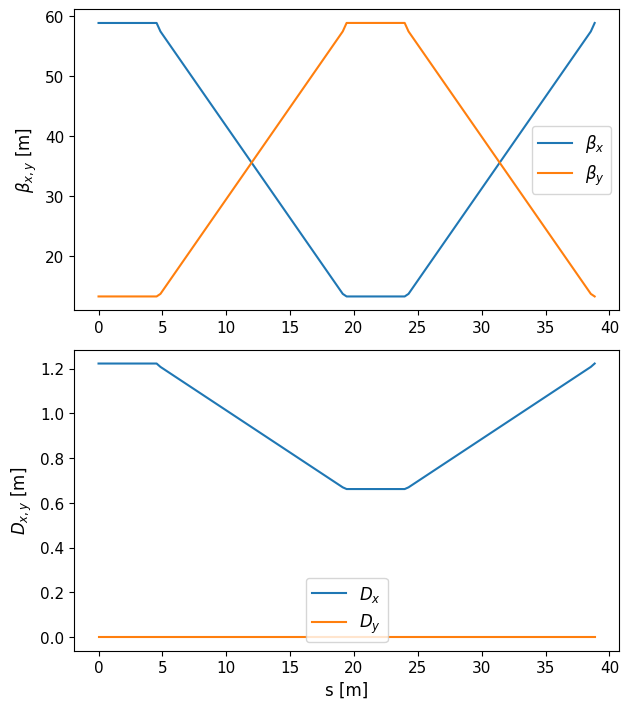

qp1 k1
qp2 k2
qp3 k3
qp4 k4
qp5 k5
                                             
Optimize - start penalty: 7.001                             
Matching: model call n. 45 penalty = 2.5016e-09              
Optimize - end penalty:  2.5016e-09                            


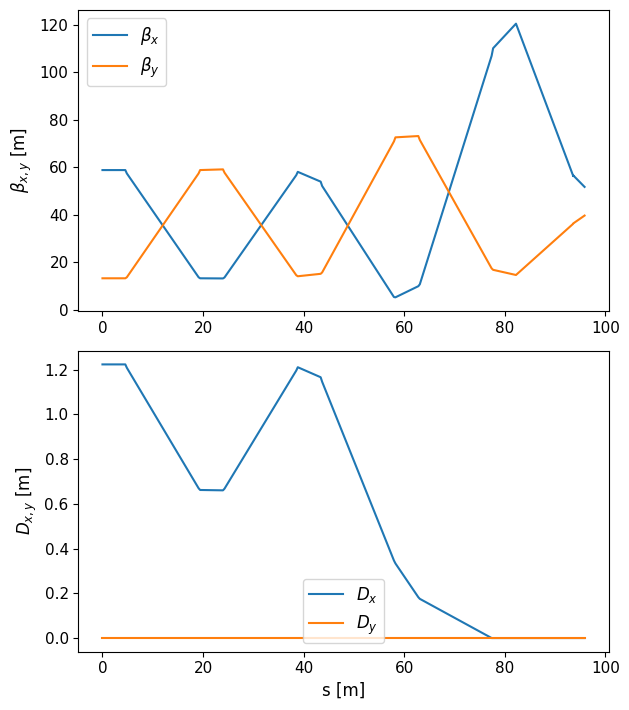

qp1 k1
qp2 k2
qp3 k3
qp4 k4
qp5 k5
                                             
Optimize - start penalty: 1.896e-07                         
Matching: model call n. 7 penalty = 7.6390e-10              
Optimize - end penalty:  7.63895e-10                            


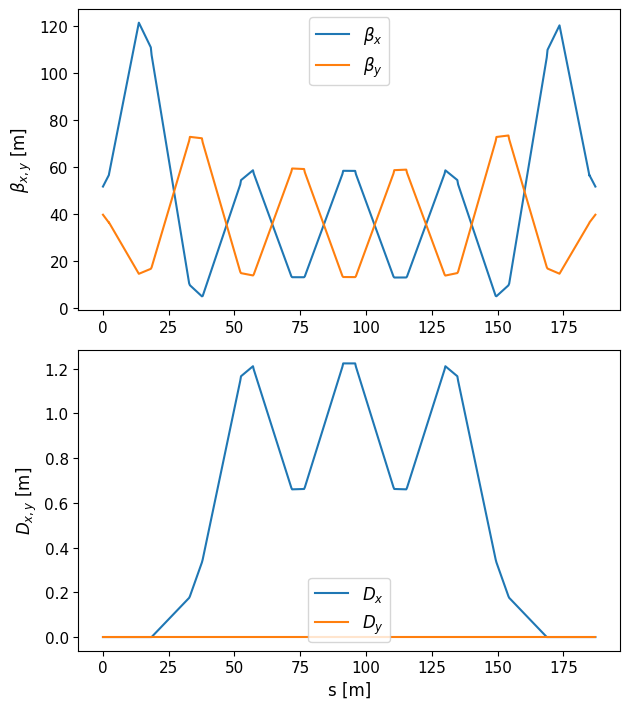

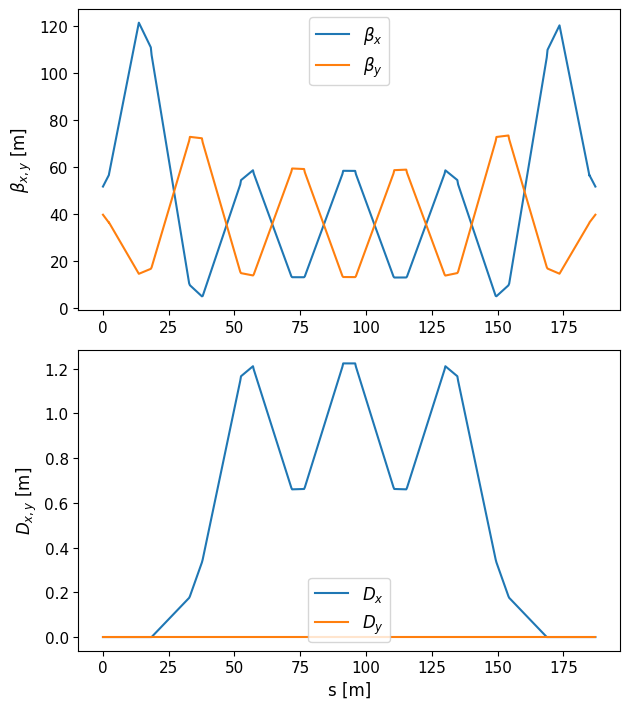

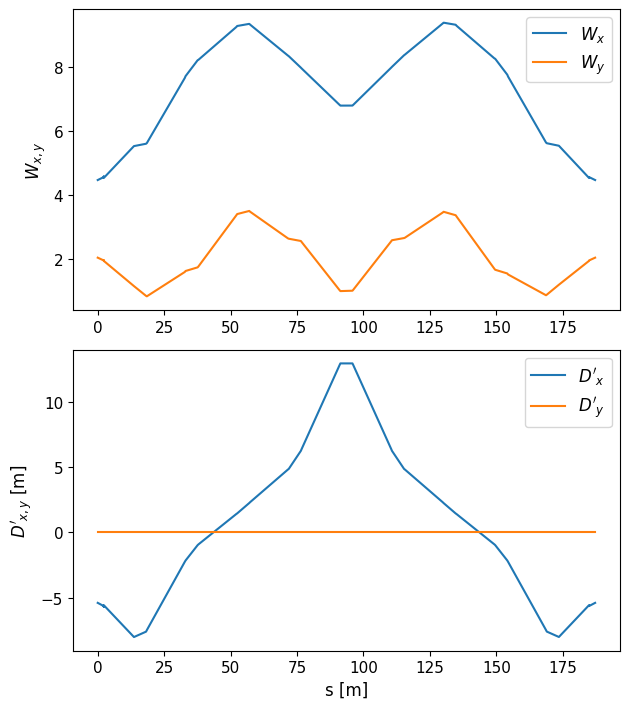

In [4]:
time_frac = 0
option = 'var_ref'

add_quad = 0
DS = DS_normal(
    rcs = rcs, 
    n_turn_rcs=n_turn_rcs, 
    time_frac=time_frac, 
    option=option, mu=mu, 
    add_quad=add_quad, 
    plot=True
    )

DS.build_arc_ds(ia = 4, knobs=[
    'k1', 
    'k2', 'k3', 'k4', 
    # 'k5', 
    # 'k6'
    
    ])
line_FODO = DS.line_FODO
line_arc = DS.line_arc
tw_arc = DS.tw_arc

fig = plot_twiss(tw_arc)
fig_chroma = plot_chroma(tw_arc)

In [ ]:
dp0c = off_dE(line_arc)
tw_arc = line_arc.twiss4d()
on_dE(line_arc, dp0c)

folder = 'lattices/lattices_final_report/' + rcs_name
save = False
if save:
    save_para(
        rcs=rcs, 
        arc=f'_{nb_arc_N}_arc', 
        folder=folder,
        rcs_name = rcs_name
        )
    save_tunes(
        tw=tw_arc, 
        rcs=rcs, 
        arc=f'_{nb_arc_N}_arc', 
        folder=folder,
        rcs_name = rcs_name
        )

    save_table(
        rcs=rcs, 
        tw_arc=tw_arc, 
        qp_para=qp_para_N, 
        n_sigma=n_size, 
        sigma_delta=sigma_delta, 
        folder=folder,
        rcs_name = rcs_name,
        add_quad = add_quad
        )

In [ ]:
if save:
    line_arc.to_json(f'/mnt/c/muco/code/{folder}/line_{rcs_name}_normal_qp_{nb_arc_N}_arc.json')
    fig.savefig(f'/mnt/c/muco/code/{folder}/twiss_{rcs_name}_normal_qp_{nb_arc_N}_arc.png')
    fig_chroma.savefig(f'/mnt/c/muco/code/{folder}/chroma_{rcs_name}_normal_qp_{nb_arc_N}_arc.png')

In [ ]:
n_part = 5000
nemitt_x = 25e-6
nemitt_y = 25e-6
nemitt_s = 0.025

input = {
    'RCS1': {
        'n_turn_rcs' : 17,
        't_acc' : 0.34e-3,
        'sigma_z' : 30.2e-12,
    }
}

rcs_name = 'RCS1'
n_turn_rcs = input[rcs_name]['n_turn_rcs']
t_acc = input[rcs_name]['t_acc']
sigma_z = input[rcs_name]['sigma_z']
nb_arc_tot = n_turn_rcs*rcs.nb_arc

In [8]:
ramp = False
method = 'var_ref'
n_sigma = 5
RF_tuning = False
adapt_part = False
plt_twiss = False
plt_sepa = True

tracking = False
if tracking:

    track_rcs = TrackingRCS(
            line = line_arc,
            rcs =rcs,
            n_turn_rcs = n_turn_rcs,
            n_part=n_part,
            nemitt_x=nemitt_x,
            nemitt_y=nemitt_y,
            sigma_z=sigma_z,
            t_acc = t_acc,
            ramp = ramp,
            n_sigma = n_sigma,
            method = method,
            RF_tuning = RF_tuning,
            adapt_part = adapt_part,
            plt_twiss = plt_twiss,
            plt_sepa = plt_sepa,
        )